<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/mse_logo.png" width="400" align="right"/>
<div style="text-align: left"> <b> Machine Learning FTP_MachLe </b> <br> HS 2026 <br> <a href="mailto:christoph.wuersch@ost.ch"> Christoph Würsch </a> </div>

In [1]:
# imports
from IPython.display import Image, display
from IPython.display import HTML
import os
import requests
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# allow plots to appear directly in the notebook
%matplotlib inline

# raw URL of this repository on GitHub (images, data)
filepath = "https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main"

# **Feature Engineering – Group 7: Text Standardization and Encoding II**

**Authors:** *Evan Vaughan, Mohammad Teimori, Jérôme McDonald*

### Instructor review (2026-10-08)

This notebook (Group 7 – Text Standardization and Encoding II) was checked against the group-work assignment. Changes are marked directly in the notebook:

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> <span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> <span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> <span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

Code changes are marked with a comment `# [ADDED]`, `# [CORRECTED]`, ... All changed cells also carry a cell tag `review-*`.

**Added**
- (ii) negative-sampling loss, CBOW formula, word analogies; short `gensim` CBOW vs. skip-gram example
- (iv) explanation of the text → tokens → contextual vectors pipeline, contextual vs. static embeddings, mean pooling, cosine similarity, semantic search
- (iv) runnable mean-pooling baseline (shows order-blindness of static vectors) and a contextual 'bank' example
- Caution on the cosine = 1.0 artefact of the template corpus (i); missing references; banner image restored

**Corrected**
- Takeaways: 'BPE gives no unknown tokens' holds only for byte-level BPE

**Revised for clarity**
- (i) LSA (word–document) vs. the word–word PPMI/SVD recipe used here
- (iv) sentence-transformers cell: explanatory print() text moved to markdown, pip install as comment
- References

**Removed (beyond course scope)**
- Work-split planning cell
- Pasted copy of the BPE code output (the executed cell now prints it)
- Reference on modern positional encodings

Cells tagged `review-skip-exec` (pretrained model from huggingface.co) were not executed during the review; the cell marked `review-needs-device-exec` (contextual 'bank' example) still has to be run once with internet access.


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> *banner image restored from the course template*

<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/images/07_Text_Encoding_2.png" width="1200"/>

<span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

*Work-split planning cell* was removed: internal planning note that the authors intended to delete before submission.

## Introduction

**What is it about?**
Bag-of-Words and TF–IDF treat words as independent symbols, so "car" and "automobile" are as different as "car" and "banana". *Word vectors* (embeddings) instead represent words as dense vectors in a space where semantic similarity corresponds to geometric closeness. Word2Vec learns such vectors from large corpora by predicting a word from its context (CBOW) or the context from a word (skip-gram). Modern language models split text into *subword* units using Byte-Pair Encoding (BPE), which handles rare and unseen words, and produce *contextual* embeddings in which the same word gets different vectors depending on its meaning in the sentence.

**Where is it used?**
Semantic search and retrieval-augmented generation (RAG), recommendation systems, machine translation, question answering, chatbots, text clustering and classification, and as input features for downstream models. Typical tools are `gensim` (Word2Vec), tokenizers from Hugging Face or `tiktoken` (BPE), and embedding models from `sentence-transformers` or LLM APIs.

**Why is it important for Machine Learning?**
Dense, semantic representations made transfer learning in NLP possible: an embedding learned on billions of words can be reused for a small task with little labelled data. Tokenization and embedding choices directly affect model quality, vocabulary coverage, cost (number of tokens) and even fairness. Understanding the path from word vectors to LLM encodings shows *how* modern language models represent meaning.

## (i) Historical view: word vectors

**The problem.** With one-hot vectors (and BoW/TF-IDF built on them) every word is its own axis: the vectors are sparse, as long as the vocabulary, and any two different words are orthogonal, so "hotel" and "motel" have similarity 0. New words cannot be represented at all.

**The idea (distributional hypothesis).** *"You shall know a word by the company it keeps"* (J. R. Firth, 1957). Words that appear in similar contexts have similar meanings, so we describe a word by *which words surround it*.

**A short timeline.**

| Year | Method | Idea |
|---|---|---|
| 1990 | LSA | factorise a word–document count matrix with SVD |
| 2013 | Word2Vec | *predict* context words with a shallow neural network |
| 2014 | GloVe | factorise global co-occurrence statistics |
| 2016 | fastText | words as bags of character n-grams, handles rare words |
| 2018+ | ELMo, BERT, GPT | one vector per word *occurrence* (contextual), subword tokens |

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> Below we build the classic count-based recipe from scratch (LSA factorises a word–document matrix; we use the closely related word–word variant) (*self-contained*): count co-occurrences in a window, keep only informative ones (positive pointwise mutual information, PPMI) and compress with SVD. The toy corpus is generated from templates so that "hotel, motel, hostel" share contexts, as do vehicles and fruit.

In [2]:
import random
random.seed(0)

# toy corpus: three groups of words that share contexts
groups = {"stay":  ["hotel", "motel", "hostel"],
          "ride":  ["car", "truck", "bus"],
          "fruit": ["apple", "banana", "orange"]}
templates = {
    "stay":  ["we booked a {w} near the beach", "the {w} had a clean room and a friendly desk",
              "she checked into the {w} late at night", "a night at the {w} was cheap"],
    "ride":  ["he parked the {w} near the station", "the {w} drove down the long road",
              "she waited for the {w} on the busy street", "a loud {w} passed on the road"],
    "fruit": ["she ate a ripe {w} for breakfast", "the {w} tasted sweet and fresh",
              "he bought a {w} at the market", "a juicy {w} lay in the basket"]}
corpus = []
for _ in range(400):
    g = random.choice(list(groups))
    corpus.append(random.choice(templates[g]).format(w=random.choice(groups[g])).split())

vocab = sorted({t for s in corpus for t in s})
idx = {w: i for i, w in enumerate(vocab)}
V = len(vocab)
print(f"{len(corpus)} sentences, vocabulary size V = {V}.  Example: {' '.join(corpus[0])}")

# one-hot: different words are always orthogonal -> similarity 0
one_hot = np.eye(V)
print("one-hot similarity(hotel, motel) =", one_hot[idx["hotel"]] @ one_hot[idx["motel"]])

400 sentences, vocabulary size V = 55.  Example: a loud car passed on the road
one-hot similarity(hotel, motel) = 0.0


cosine(hotel, motel)  = 1.0
cosine(hotel, banana) = 0.03
nearest to hotel : [('motel', 1.0), ('hostel', 1.0), ('night', 0.96)]
nearest to car   : [('truck', 1.0), ('bus', 1.0), ('busy', 0.99)]
nearest to apple : [('banana', 1.0), ('orange', 1.0), ('basket', 0.85)]


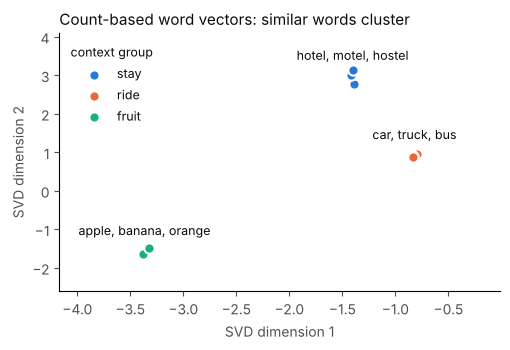

In [3]:
# 1) co-occurrence counts in a window of +-m words
m = 2
C = np.zeros((V, V))
for s in corpus:
    for i, w in enumerate(s):
        for j in range(max(0, i - m), min(len(s), i + m + 1)):
            if j != i:
                C[idx[w], idx[s[j]]] += 1

# 2) PPMI: keep only pairs that co-occur more often than chance
tot = C.sum(); p_w = C.sum(1, keepdims=True) / tot; p_c = C.sum(0, keepdims=True) / tot
with np.errstate(divide="ignore"):
    pmi = np.log((C / tot) / (p_w * p_c))
ppmi = np.where(np.isfinite(pmi) & (pmi > 0), pmi, 0)

# 3) SVD: dense low-dimensional word vectors
U, S, _ = np.linalg.svd(ppmi)
E_svd = U[:, :8] * S[:8]                      # 8-dimensional word vectors

def cos(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))
def neighbors(E, word, k=3):
    sims = sorted(((cos(E[idx[word]], E[i]), vocab[i]) for i in range(V) if vocab[i] != word), reverse=True)
    return [(w, round(s, 2)) for s, w in sims[:k]]

print("cosine(hotel, motel)  =", round(cos(E_svd[idx["hotel"]], E_svd[idx["motel"]]), 2))
print("cosine(hotel, banana) =", round(cos(E_svd[idx["hotel"]], E_svd[idx["banana"]]), 2))
for w in ["hotel", "car", "apple"]:
    print(f"nearest to {w:6s}:", neighbors(E_svd, w))

# visualise the first two SVD dimensions of the nine group words
INK, MUTED = "#0b0b0b", "#52514e"
COLORS = {"stay": "#2a78d6", "ride": "#eb6834", "fruit": "#1baf7a"}
plt.rcParams.update({"text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})
fig, ax = plt.subplots(figsize=(5.2, 3.6))
for g, ws in groups.items():
    pts = np.array([E_svd[idx[w], :2] for w in ws])
    ax.scatter(pts[:, 0], pts[:, 1], s=55, color=COLORS[g], edgecolor="white", linewidth=1.5, label=g)
    ax.annotate(", ".join(ws), pts.mean(axis=0), xytext=(0, 12), textcoords="offset points",
                ha="center", fontsize=9)          # one label per group (the words nearly coincide)
ax.margins(x=0.3, y=0.2)
ax.set_xlabel("SVD dimension 1"); ax.set_ylabel("SVD dimension 2")
ax.set_title("Count-based word vectors: similar words cluster", fontsize=11, loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9, title="context group", title_fontsize=9)
plt.tight_layout(); plt.show()

SVD turns sparse, high-dimensional counts into dense vectors in which words from the same group are close. The weakness of this recipe is cost and flexibility: the matrix grows with the vocabulary, and adding data means re-factorising it. Word2Vec arrives at similar vectors by *learning* them incrementally.

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> *Caution:* cosine = 1.0 for hotel/motel is an artefact of the template corpus, in which these words are perfectly interchangeable. On real text, related words score clearly below 1, and neighbours learned from toy corpora are noisy.

## (ii) Word2Vec: skip-gram and CBOW

Word2Vec (Mikolov et al., 2013) trains a shallow network on a *fake task*: slide a window of size $m$ over the text and predict words from their neighbours. The task itself is not the goal; the **learned input vectors** $v_w$ are the embeddings.

- **CBOW** (continuous bag of words): average the context vectors and predict the **target** word. Fast, good for frequent words.
- **Skip-gram**: take the **target** word and predict each **context** word. Slower, but better for rare words.

For skip-gram the loss over a text of $T$ words is

$$J(\theta) = -\frac{1}{T}\sum_{t=1}^{T}\;\sum_{-m\le j\le m,\; j\neq 0}\log P(w_{t+j}\mid w_t), \qquad P(o\mid c)=\frac{\exp(u_o^{\top}v_c)}{\sum_{w\in V}\exp(u_w^{\top}v_c)}$$

The probability is large if the dot product $u_o^{\top}v_c$ is large, so words that often share contexts are pushed to similar vectors. The denominator sums over the whole vocabulary and is expensive, so in practice **negative sampling** is used: raise the score of the true pair and lower it for $K$ randomly drawn "noise" words. Every word has two vectors, $v$ (as target) and $u$ (as context); we keep $v$.

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>
For one (target $c$, context $o$) pair, the **negative-sampling loss** implemented in the code below is

$$\ell = -\log\sigma(u_o^{\top}v_c) \;-\; \sum_{k=1}^{K}\log\sigma(-u_{w_k}^{\top}v_c),\qquad w_k\sim P_n(w)\propto f(w)^{3/4},$$

i.e. $K+1$ binary logistic regressions instead of a $|V|$-way softmax ($f(w)$ = word frequency). **CBOW** uses the same machinery, but replaces $v_c$ by the average of the context vectors, $\bar v=\frac{1}{2m}\sum_{j\neq 0}v_{t+j}$, and predicts the centre word $w_t$.

**Analogies.** Trained on large corpora, vector *offsets* encode relations: $v_{\text{king}}-v_{\text{man}}+v_{\text{woman}}\approx v_{\text{queen}}$ (nearest neighbour by cosine, query words excluded; in gensim `wv.most_similar(positive=["king", "woman"], negative=["man"])`). This needs millions of training words; on toy corpora analogies are not reliable.

CBOW      (many -> one): ['the', 'quick', 'fox', 'jumps'] -> brown
Skip-gram (one -> many): [('brown', 'the'), ('brown', 'quick'), ('brown', 'fox'), ('brown', 'jumps')]


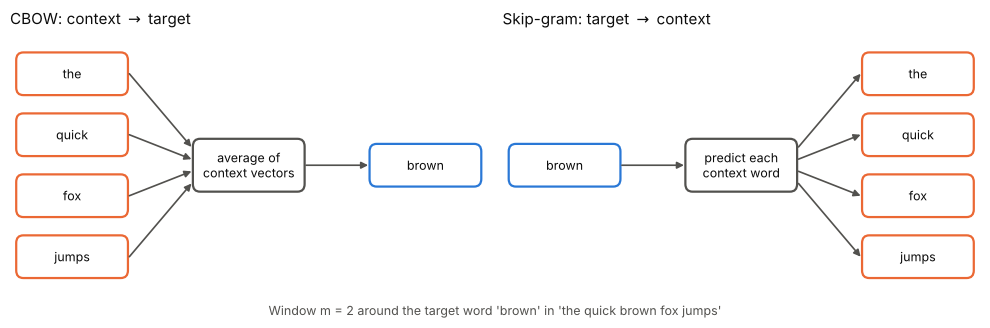

In [4]:
sentence, m_demo, t = "the quick brown fox jumps".split(), 2, 2      # target = "brown"
context = [sentence[j] for j in range(max(0, t - m_demo), min(len(sentence), t + m_demo + 1)) if j != t]
print("CBOW      (many -> one):", context, "->", sentence[t])
print("Skip-gram (one -> many):", [(sentence[t], c) for c in context])

# schematic of both architectures
from matplotlib.patches import FancyBboxPatch
def box(ax, x, y, text, edge, fill="white", w=2.3, h=0.8):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                edgecolor=edge, facecolor=fill, linewidth=1.6))
    ax.text(x, y, text, ha="center", va="center", fontsize=9, color=INK)
def arrow(ax, p, q):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2, shrinkA=0, shrinkB=0))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
ys = [4.2, 3.0, 1.8, 0.6]
for ax, title in zip(axes, ["CBOW: context $\\rightarrow$ target", "Skip-gram: target $\\rightarrow$ context"]):
    ax.set_xlim(0, 10); ax.set_ylim(0, 5); ax.axis("off"); ax.set_title(title, fontsize=11, loc="left")
# CBOW (left)
for y, w in zip(ys, context):
    box(axes[0], 1.3, y, w, "#eb6834"); arrow(axes[0], (2.5, y), (3.8, 2.4 + 0.2 * (y - 2.4)))   # spread the arrow heads
box(axes[0], 5.0, 2.4, "average of\ncontext vectors", MUTED, h=1.0); arrow(axes[0], (6.2, 2.4), (7.5, 2.4))
box(axes[0], 8.7, 2.4, "brown", "#2a78d6")
# skip-gram (right)
box(axes[1], 1.3, 2.4, "brown", "#2a78d6"); arrow(axes[1], (2.5, 2.4), (3.8, 2.4))
box(axes[1], 5.0, 2.4, "predict each\ncontext word", MUTED, h=1.0)
for y, w in zip(ys, context):
    arrow(axes[1], (6.2, 2.4 + 0.2 * (y - 2.4)), (7.5, y)); box(axes[1], 8.7, y, w, "#eb6834")
fig.text(0.5, 0.0, "Window m = 2 around the target word 'brown' in 'the quick brown fox jumps'", ha="center", fontsize=9, color=MUTED)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

**Self-contained example.** We train skip-gram with negative sampling in about 25 lines of `numpy` on the toy corpus from (i). The loss falls quickly and words from the same group end up close together.

nearest to hotel : [('motel', 0.99), ('hostel', 0.97), ('night', 0.71)]
nearest to car   : [('bus', 0.97), ('truck', 0.97), ('beach', 0.64)]
nearest to apple : [('banana', 0.97), ('orange', 0.96), ('basket', 0.63)]


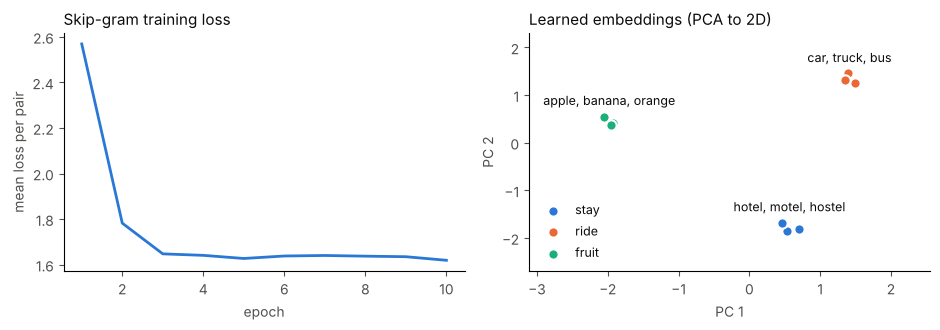

In [5]:
rng = np.random.default_rng(1)
d, K, lr, epochs = 16, 5, 0.05, 10
W_in  = rng.normal(0, 0.1, (V, d))            # v: target vectors = the embeddings we keep
W_out = rng.normal(0, 0.1, (V, d))            # u: context vectors
freq = np.array([sum(s.count(w) for s in corpus) for w in vocab], float) ** 0.75
p_neg = freq / freq.sum()                     # noise distribution (unigram^0.75)
pairs = [(idx[s[i]], idx[s[j]]) for s in corpus for i in range(len(s))
         for j in range(max(0, i - m), min(len(s), i + m + 1)) if j != i]   # (target, context)
sigmoid = lambda x: 1 / (1 + np.exp(-x))

losses = []
for ep in range(epochs):
    rng.shuffle(pairs); L = 0
    for t, c in pairs:
        neg = rng.choice(V, K, p=p_neg)       # K noise words
        v = W_in[t]
        s_pos, s_neg = sigmoid(W_out[c] @ v), sigmoid(-(W_out[neg] @ v))
        L += -np.log(s_pos + 1e-9) - np.log(s_neg + 1e-9).sum()
        grad_v = (s_pos - 1) * W_out[c] + ((1 - s_neg)[:, None] * W_out[neg]).sum(0)
        W_out[c] -= lr * (s_pos - 1) * v
        np.add.at(W_out, neg, -lr * (1 - s_neg)[:, None] * v)
        W_in[t]  -= lr * grad_v
    losses.append(L / len(pairs))

for w in ["hotel", "car", "apple"]:
    print(f"nearest to {w:6s}:", neighbors(W_in, w))

from sklearn.decomposition import PCA
words9 = [w for ws in groups.values() for w in ws]
P = PCA(n_components=2).fit_transform(W_in[[idx[w] for w in words9]])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.4))
a1.plot(range(1, epochs + 1), losses, color="#2a78d6", lw=2)
a1.set_xlabel("epoch"); a1.set_ylabel("mean loss per pair")
a1.set_title("Skip-gram training loss", fontsize=11, loc="left")
for g, ws in groups.items():
    pts = np.array([P[words9.index(w)] for w in ws])
    a2.scatter(pts[:, 0], pts[:, 1], s=55, color=COLORS[g], edgecolor="white", linewidth=1.5, label=g)
    a2.annotate(", ".join(ws), pts.mean(axis=0), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=9)
a2.margins(x=0.3, y=0.25)
a2.set_title("Learned embeddings (PCA to 2D)", fontsize=11, loc="left")
a2.set_xlabel("PC 1"); a2.set_ylabel("PC 2"); a2.legend(frameon=False, fontsize=9)
for a in (a1, a2): a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**The same in practice with `gensim`.** One argument switches between the two architectures: `sg=0` (CBOW) and `sg=1` (skip-gram). On a corpus this tiny both give almost the same neighbours; the textbook differences (CBOW faster and smoother for frequent words, skip-gram better for rare words) only show on large corpora. Toy results are noisy and change with the random seed.

In [6]:
# [ADDED]
from gensim.models import Word2Vec

for sg, name in [(0, "CBOW"), (1, "skip-gram")]:
    w2v = Word2Vec(sentences=corpus, vector_size=16, window=m, min_count=1, sg=sg,
                   negative=5, epochs=30, seed=1, workers=1)   # workers=1 for reproducibility
    print(f"{name:9s}", {w: [n for n, _ in w2v.wv.most_similar(w, topn=3)] for w in ["hotel", "car", "apple"]})

CBOW      {'hotel': ['motel', 'hostel', 'night'], 'car': ['truck', 'bus', 'passed'], 'apple': ['banana', 'orange', 'breakfast']}
skip-gram {'hotel': ['motel', 'hostel', 'night'], 'car': ['truck', 'bus', 'road'], 'apple': ['banana', 'orange', 'basket']}


## (iii) Byte-Pair Encoding (BPE)

**Why use subwords?** A whole-word vocabulary struggles with unfamiliar names and word forms. Character tokens cover more words but produce long sequences. **BPE learns reusable text pieces** between these extremes. It was adapted from compression to NLP to help represent rare and unseen words. [Sennrich et al., section 3.2](https://aclanthology.org/P16-1162.pdf)

**How training works:**

1. Start with individual characters in this teaching example.
2. Count pairs of **neighboring current tokens**, weighted by word frequency.
3. Merge the most frequent pair into one token; save the rule.
4. Recount and repeat until a chosen vocabulary size or merge limit is reached.

Each merge adds a vocabulary entry while shortening affected sequences. For **new text**, reuse the saved merge rules in their learned order; do not learn new rules from that text. [Hugging Face: BPE](https://huggingface.co/docs/course/en/chapter6/5)

**A tiny example we can calculate by hand:**

| Training word | Frequency | Starting pieces |
| --- | ---: | --- |
| `low` | 5 | `l · o · w` |
| `lower` | 2 | `l · o · w · e · r` |
| `slow` | 3 | `s · l · o · w` |

The pair `l, o` occurs `5 + 2 + 3 = 10` times. It ties with `o, w`; our code resolves ties alphabetically. After merging to `lo`, the pair `lo, w` also occurs ten times. The next winning pair is `s, low`, occurring three times.

The following cell learns those three rules and applies them to **`slower`**, a word absent from the training vocabulary. It uses only Python's standard library.


In [7]:
from collections import Counter

frequencies = {"low": 5, "lower": 2, "slow": 3}
splits = {word: list(word) for word in frequencies}

def merge_pair(pieces, pair):
    merged = []
    i = 0
    while i < len(pieces):
        if tuple(pieces[i:i + 2]) == pair:
            merged.append("".join(pair))
            i += 2  # Consume both neighboring pieces.
        else:
            merged.append(pieces[i])
            i += 1
    return merged

merges = []
for step in range(3):
    counts = Counter()
    for word, pieces in splits.items():
        for pair in zip(pieces, pieces[1:]):
            counts[pair] += frequencies[word]
    pair = min(counts, key=lambda p: (-counts[p], p))  # Frequency, then alphabet.
    merges.append(pair)
    splits = {word: merge_pair(pieces, pair) for word, pieces in splits.items()}
    print(f"Merge {step + 1}: {' + '.join(pair)} -> {''.join(pair)} (count={counts[pair]})")

word = "slower"
assert word not in frequencies and set(word) <= set("".join(frequencies))
encoded = list(word)
for pair in merges:
    encoded = merge_pair(encoded, pair)
print(f"\nUnseen word: {word} -> {encoded}")
assert "".join(encoded) == word  # No text was lost.


Merge 1: l + o -> lo (count=10)
Merge 2: lo + w -> low (count=10)
Merge 3: s + low -> slow (count=3)

Unseen word: slower -> ['slow', 'e', 'r']


<span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

*Markdown cell with a pasted copy of the BPE output* was removed: redundant – the code cell above now prints the merges when executed.

**Read the result:** `slower` changes from `s · l · o · w · e · r` to `s · lo · w · e · r`, then `s · low · e · r`, and finally `slow · e · r`: **three tokens instead of six characters**. Known pieces can represent an unseen whole word. The split is frequency-driven; it need not match grammar (`slow + er`).

**Practical limits:** This is a character-based, word-by-word illustration with a known alphabet. It omits whitespace, punctuation, special tokens, and unknown-character handling. Byte-level BPE can start with all 256 byte values to cover UTF-8 text. BPE supplies tokens/IDs; the model's embedding layer supplies learned vectors. Use the tokenizer associated with your pretrained model. [Hugging Face: tokenization algorithms](https://huggingface.co/docs/transformers/en/tokenizer_summary)

## (iv) Modern encodings using LLMs



<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**From text to contextual vectors.** An LLM-based encoder maps text to vectors in three steps:

1. **Tokenize** with the model's own subword tokenizer (BPE or a relative, section iii) → token IDs.
2. **Look up** one static vector per ID in a learned embedding table (the analogue of Word2Vec's $v_w$).
3. **Transformer layers** let every token vector take in information from all other tokens of the input (self-attention), so the output vector $h_i$ of token $i$ depends on its context. The internals of attention and positional encodings are beyond this course.

**Contextual embeddings.** Word2Vec has *one* vector per word type, so the senses of "bank" (river vs. money) are blended. A Transformer gives *one vector per occurrence*: "bank" in *river bank* and in *bank loan* gets different vectors.

**Sentence embeddings.** Pool the token vectors of a sentence into one fixed-length vector, typically by **mean pooling** $s=\frac{1}{n}\sum_{i=1}^{n}h_i$ (or by using a special `[CLS]` token). Sentence-embedding models such as Sentence-BERT (`all-MiniLM-L6-v2`, 384 dimensions) are fine-tuned so that paraphrases end up close together.

**Cosine similarity** $\cos(a,b)=\dfrac{a^{\top}b}{\lVert a\rVert\,\lVert b\rVert}\in[-1,1]$ compares directions and ignores vector length. For normalised embeddings it equals the dot product.

**Semantic search** embeds all documents once, embeds the query, and ranks documents by cosine similarity (nearest-neighbour search). This is the retrieval step of RAG.

*Baseline (runs anywhere):* mean-pooling **static** vectors (here the skip-gram vectors `W_in` from (ii)) already gives a crude sentence embedding, but it ignores word order and context.

In [8]:
# [ADDED]
def sent_vec(text):                          # mean pooling of static word vectors
    return W_in[[idx[w] for w in text.split()]].mean(axis=0)

pairs_iv = [("she ate a ripe banana", "the apple tasted sweet and fresh"),   # same topic
            ("she ate a ripe banana", "he parked the truck near the station"),  # different topic
            ("the car passed the bus", "the bus passed the car")]               # different meaning!
for a, b in pairs_iv:
    print(f"cos = {cos(sent_vec(a), sent_vec(b)):5.2f}   '{a}'  vs  '{b}'")

cos =  0.57   'she ate a ripe banana'  vs  'the apple tasted sweet and fresh'
cos =  0.37   'she ate a ripe banana'  vs  'he parked the truck near the station'
cos =  1.00   'the car passed the bus'  vs  'the bus passed the car'


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

The topic is captured, but the last two sentences get cosine 1.0 although they mean different things: averaging static vectors is order-blind. Contextual models fix this. The pretrained example below (from the students' run) needs `sentence-transformers` and a model download from huggingface.co: the related pair shares **no** content word, so TF–IDF would give cosine 0, yet its embedding similarity is much higher than for the unrelated pair. Absolute values depend on the model; only the ranking is meaningful.

In [ ]:
# [REVISED] explanatory print() text moved to the markdown cell above; '!pip install' turned into a comment. Stored output = students' run (trimmed to the result lines)
# pip install sentence-transformers   (once; downloads all-MiniLM-L6-v2 from huggingface.co on first use)
from sentence_transformers import SentenceTransformer, util

model = SentenceTransformer('all-MiniLM-L6-v2')

sentences = [
    "The puppy chased the ball.", # Query
    "A young dog ran after a toy.", # Semantically related
    "CPU and GPU are computer processors." # Unrelated
]

# Encode and compute similarity
embs = model.encode(sentences, convert_to_tensor=True)
sim_related = util.cos_sim(embs[0], embs[1]).item()
sim_unrelated = util.cos_sim(embs[0], embs[2]).item()

print(f"Query: '{sentences[0]}'")
print(f"Related similarity: {sim_related:.4f}")
print(f"Unrelated similarity: {sim_unrelated:.4f}")

Query: 'The puppy chased the ball.'
Related similarity: 0.5574
Unrelated similarity: 0.0234


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Contextual embeddings in action** (needs the model above). We extract the output vector of the token "bank" in three sentences. A static model would give cosine 1.0 for every pair; a contextual model should give a clearly lower value for the *river* sense than between the two *money* senses.

In [ ]:
# [ADDED] needs sentence-transformers + model download; run on a machine with internet access
bank_sents = ["He sat on the bank of the river.",
              "She deposited the cash at the bank.",
              "The bank approved the loan."]

def token_vec(sentence, word="bank"):
    ids = model.tokenizer(sentence)["input_ids"]                       # includes [CLS] at position 0
    pos = ids.index(model.tokenizer.convert_tokens_to_ids(word))
    return model.encode(sentence, output_value="token_embeddings")[pos]   # contextual vector h_pos

h = [token_vec(s) for s in bank_sents]
print(f"bank(river) vs bank(cash): {util.cos_sim(h[0], h[1]).item():.2f}")
print(f"bank(river) vs bank(loan): {util.cos_sim(h[0], h[2]).item():.2f}")
print(f"bank(cash)  vs bank(loan): {util.cos_sim(h[1], h[2]).item():.2f}")

<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *'no unknown tokens' holds only for byte-level BPE; one bullet on sentence embeddings added*

## Takeaways

- **What should every ML practitioner remember?**
  - One-hot, BoW and TF–IDF cannot express similarity; dense embeddings can, because they are learned from context ("a word is known by the company it keeps").
  - Word2Vec = a fake prediction task. CBOW predicts the target from its context (fast), skip-gram predicts the context from the target (better for rare words). The embeddings are the learned input weights.
  - BPE builds a vocabulary of frequent subwords by repeatedly merging the most frequent adjacent pair; the vocabulary size is controllable, and *byte-level* BPE never produces unknown tokens (character-level BPE still fails on characters never seen in training).
  - Modern LLMs = subword tokens + embedding table + Transformer layers, giving **contextual** vectors; one word type has many vectors. Sentence embeddings (mean-pooled token vectors) + cosine similarity = semantic search.
- **What are common pitfalls?**
  - Static vectors blend all senses of a word (polysemy) and cannot handle unseen words (except fastText).
  - Embeddings copy the **bias** of their training data (e.g. gender stereotypes for professions).
  - Cosine similarity of embeddings is only meaningful within *one* model; never mix vectors from different models or tokenizers.
  - Tokenization surprises: non-English text, numbers, rare words and whitespace produce more tokens, which costs money and context length; always use the tokenizer that belongs to the model.
  - Too small a toy corpus or too few epochs gives meaningless neighbours.
- **When does this technique really matter?**
  - Little labelled data: start from pretrained embeddings (transfer learning) instead of BoW.
  - Semantic search, recommendation, clustering and RAG, where meaning must match without shared keywords.
  - Domain-specific text (medicine, code, other languages): check that the tokenizer and embeddings fit, or train your own.
  - For small, keyword-driven tasks TF–IDF is still a strong, cheap and interpretable baseline.

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *added missing sources (BPE paper, tokenizer summary, Sentence-BERT, model card); removed a link on positional encodings (beyond course scope)*

## References

*Cite the sources of all figures, diagrams and code snippets (URLs are sufficient).*

1. Lecture slides V04 Feature Engineering, Chr. Würsch, OST (FTP_MachLe HS 2026), slides on word embeddings, Word2Vec (skip-gram, CBOW) and bias in word vectors.
2. J. R. Firth (1957): *A synopsis of linguistic theory 1930–1955.* In: Studies in Linguistic Analysis, Blackwell, Oxford, pp. 1–32. (source of "You shall know a word by the company it keeps")
3. S. Deerwester, S. Dumais, G. Furnas, T. Landauer, R. Harshman (1990): *Indexing by Latent Semantic Analysis.* Journal of the American Society for Information Science 41(6), 391–407. (LSA: SVD of count matrices)
4. T. Mikolov, K. Chen, G. Corrado, J. Dean (2013): *Efficient Estimation of Word Representations in Vector Space.* https://arxiv.org/abs/1301.3781
5. T. Mikolov, I. Sutskever, K. Chen, G. Corrado, J. Dean (2013): *Distributed Representations of Words and Phrases and their Compositionality* (negative sampling). https://arxiv.org/abs/1310.4546
6. J. Pennington, R. Socher, C. Manning (2014): *GloVe: Global Vectors for Word Representation.* https://nlp.stanford.edu/projects/glove/
7. O. Levy, Y. Goldberg, I. Dagan (2015): *Improving Distributional Similarity with Lessons Learned from Word Embeddings* (PPMI + SVD). https://aclanthology.org/Q15-1016/
8. P. Bojanowski, E. Grave, A. Joulin, T. Mikolov (2016): *Enriching Word Vectors with Subword Information* (fastText). https://arxiv.org/abs/1607.04606
9. M. Peters et al. (2018): *Deep contextualized word representations* (ELMo). https://arxiv.org/abs/1802.05365
10. J. Devlin, M.-W. Chang, K. Lee, K. Toutanova (2018): *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.* https://arxiv.org/abs/1810.04805
11. T. Bolukbasi, K.-W. Chang, J. Zou, V. Saligrama, A. Kalai (2016): *Man is to Computer Programmer as Woman is to Homemaker? Debiasing Word Embeddings.* https://arxiv.org/abs/1607.06520
12. J. Alammar: *The Illustrated Word2vec.* https://jalammar.github.io/illustrated-word2vec/
13. C. McCormick (2016): *Word2Vec Tutorial – The Skip-Gram Model.* https://mccormickml.com/2016/04/19/word2vec-tutorial-the-skip-gram-model/
14. gensim documentation, `Word2Vec`: https://radimrehurek.com/gensim/models/word2vec.html ; pretrained vectors (`glove-wiki-gigaword-50`) via gensim-data: https://github.com/piskvorky/gensim-data
15. Hugging Face LLM course, ch. 6.5: *Byte-Pair Encoding tokenization.* https://huggingface.co/learn/llm-course/en/chapter6/5
16. R. Sennrich, B. Haddow, A. Birch (2016): *Neural Machine Translation of Rare Words with Subword Units* (BPE). https://aclanthology.org/P16-1162/
17. Hugging Face Transformers docs: *Summary of the tokenizers* (byte-level BPE). https://huggingface.co/docs/transformers/en/tokenizer_summary
18. N. Reimers, I. Gurevych (2019): *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks.* https://arxiv.org/abs/1908.10084
19. Model card `all-MiniLM-L6-v2`: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2 ; sentence-transformers docs: https://sbert.net
